## 11. Retratos de fase e pontos críticos

No Notebook 10 vimos que as soluções de um sistema de duas EDOs podem ser desenhadas como **trajetórias** no plano de fase, e que o conjunto dessas trajetórias forma o **retrato de fase** do sistema. Vimos também que, no Exemplo 10.5, todas as trajetórias convergiam para a origem, um **ponto crítico** do sistema.

Neste notebook vamos conhecer os cinco tipos de ponto crítico de um sistema linear $\mathbf{y}'=\mathbf{A}\mathbf{y}$ — **nó impróprio**, **nó próprio**, **ponto de sela**, **centro** e **ponto espiral** — e aprender a reconhecê-los **pelo desenho** do retrato de fase. A explicação de *por que* cada matriz $\mathbf{A}$ produz um desses desenhos depende dos autovalores de $\mathbf{A}$ e ficará para o Notebook 14, depois de estudarmos autovalores e autovetores (Notebooks 12 e 13).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
sp.init_printing()

### 11.1 Pontos críticos e retrato de fase

Um **ponto crítico** (ou ponto de equilíbrio) de um sistema autônomo é um ponto onde $\mathbf{y}'=\mathbf{0}$: uma trajetória que começa nele fica parada ali para sempre. Para o sistema linear homogêneo $\mathbf{y}'=\mathbf{A}\mathbf{y}$, a origem $\mathbf{y}=\mathbf{0}$ é sempre um ponto crítico — e é o único quando $\mathbf{A}$ é invertível ($\det\mathbf{A}\neq0$), que é o caso de todos os exemplos deste notebook.

O tipo do ponto crítico é dado pela forma geométrica das trajetórias perto dele. Para desenhar os retratos de fase ao longo do notebook, vamos usar a função `retrato_de_fase`, que junta o que fizemos no Notebook 10: as linhas de fluxo (`streamplot`) do campo $\mathbf{A}\mathbf{y}+\mathbf{b}$ e algumas trajetórias calculadas com `solve_ivp` a partir de pontos iniciais dados. Cada trajetória é calculada para a frente ($t>0$) e para trás ($t<0$) no tempo, para mostrar a curva inteira que passa pelo ponto inicial; a integração é interrompida (com um *evento* do `solve_ivp`) quando a trajetória sai para longe da janela do gráfico.

In [2]:
def retrato_de_fase(A, b=(0, 0), xlim=(-4, 4), ylim=(-3, 3), iniciais=(), T=20, ax=None):
    """Desenha o retrato de fase de y' = A y + b: linhas de fluxo, trajetórias que
    passam pelos pontos em `iniciais` (calculadas para t em [-T, T], parando quando
    saem da janela) e o ponto crítico."""
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    if ax is None:
        ax = plt.gca()
    Y1, Y2 = np.meshgrid(np.linspace(*xlim, 30), np.linspace(*ylim, 30))
    V1 = A[0,0]*Y1 + A[0,1]*Y2 + b[0]
    V2 = A[1,0]*Y1 + A[1,1]*Y2 + b[1]
    ax.streamplot(Y1, Y2, V1, V2, color='lightblue', density=1.2, linewidth=1)

    F = lambda t, y: A @ y + b
    # evento: interrompe a integração quando a trajetória se afasta bastante da janela
    cx, cy = np.mean(xlim), np.mean(ylim)
    lx, ly = xlim[1] - xlim[0], ylim[1] - ylim[0]
    fora = lambda t, y: max(abs(y[0] - cx)/lx, abs(y[1] - cy)/ly) - 1
    fora.terminal = True
    for y0 in iniciais:
        for t_final in (T, -T):                      # para a frente e para trás no tempo
            s = solve_ivp(F, (0, t_final), y0, max_step=0.02, events=fora)
            ax.plot(s.y[0], s.y[1], 'r-', lw=1.2)
        ax.plot(*y0, 'ko', ms=3)

    if np.linalg.det(A) != 0:
        eq = np.linalg.solve(A, -b)
        ax.plot(*eq, 'o', color='navy', ms=6)        # ponto crítico
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel('$y_1$'); ax.set_ylabel('$y_2$')
    return ax

**Exemplo 11.1:** *Nó impróprio.* Retomando o sistema do Exemplo 10.5,

$$
\mathbf{y}^{\prime}=\left[\begin{array}{rr}
-3 & 1 \\
1 & -3
\end{array}\right] \mathbf{y},
$$

vimos que todas as trajetórias se aproximam da origem quando $t\to\infty$ e que, perto dela, chegam tangentes a uma mesma reta ($y_2=y_1$). Um ponto crítico com esse comportamento é um **nó impróprio**: todas as trajetórias (exceto duas) entram no ponto com a mesma direção tangente.

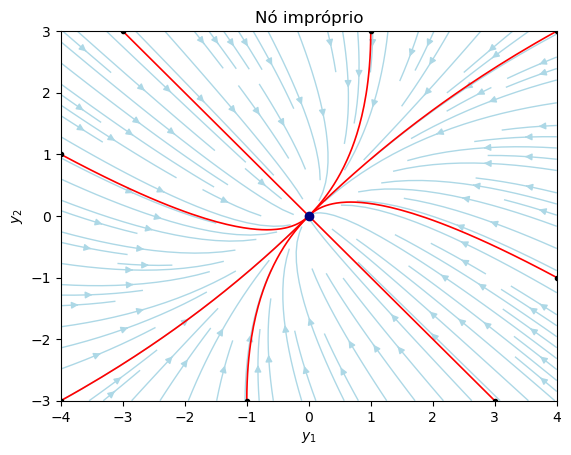

In [3]:
iniciais = [(-4, 1), (-3, 3), (4, -1), (3, -3), (1, 3), (-1, -3), (4, 3), (-4, -3)]
retrato_de_fase([[-3, 1], [1, -3]], iniciais=iniciais)
plt.title('Nó impróprio')
plt.show()

### 11.2 Nó próprio

**Exemplo 11.2:** O sistema

$$
\mathbf{y}^{\prime}=\left[\begin{array}{ll}
1 & 0 \\
0 & 1
\end{array}\right] \mathbf{y}, \quad \text { portanto, } \quad \begin{aligned}
& y_1^{\prime}=y_1 \\
& y_2^{\prime}=y_2
\end{aligned}
$$

é **desacoplado**: cada equação envolve uma só incógnita e pode ser resolvida separadamente, como uma EDO de 1ª ordem (Notebook 4). Obtemos $y_1=c_1e^t$ e $y_2=c_2e^t$, ou seja,

$$\mathbf{y}(t)=\binom{c_1}{c_2}e^t.$$

Para cada escolha de $c_1$ e $c_2$, o vetor $\mathbf{y}(t)$ tem sempre a mesma direção $(c_1,c_2)$ e só o seu comprimento varia: as trajetórias são **semirretas** saindo da origem, em todas as direções. Um ponto crítico assim é um **nó próprio**.

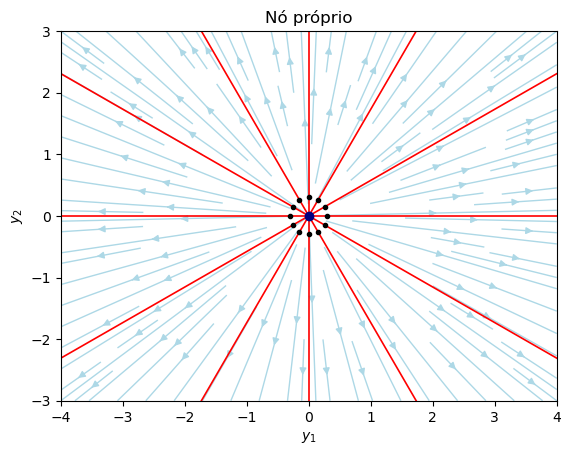

In [4]:
ang = np.linspace(0, 2*np.pi, 12, endpoint=False)
iniciais = [(0.3*np.cos(a), 0.3*np.sin(a)) for a in ang]
retrato_de_fase([[1, 0], [0, 1]], iniciais=iniciais)
plt.title('Nó próprio')
plt.show()

Aqui as trajetórias **se afastam** da origem quando $t\to\infty$ (o fator $e^t$ cresce). Se a matriz fosse $-\mathbf{I}$, as mesmas semirretas seriam percorridas no sentido contrário, em direção à origem.

### 11.3 Ponto de sela

**Exemplo 11.3:** O sistema

$$
\mathbf{y}^{\prime}=\left[\begin{array}{ll}
1 & 0 \\
0 & -1
\end{array}\right] \mathbf{y}, \quad \text { portanto, } \quad \begin{aligned}
& y_1^{\prime}=y_1 \\
& y_2^{\prime}=-y_2
\end{aligned}
$$

também é desacoplado: $y_1=c_1e^t$ e $y_2=c_2e^{-t}$. Multiplicando, $y_1y_2=c_1c_2$ é constante ao longo de cada solução, então as trajetórias estão sobre as **hipérboles** $y_1y_2=k$. Os eixos coordenados também são trajetórias ($c_1=0$ ou $c_2=0$): sobre o eixo $y_2$ a solução se aproxima da origem, e sobre o eixo $y_1$ se afasta.

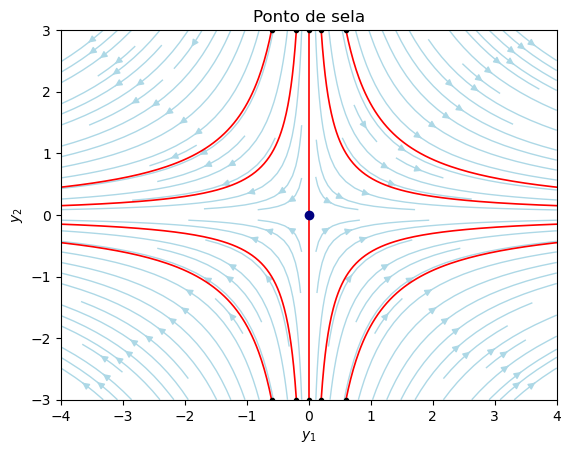

In [5]:
iniciais = [(0.2, 3), (-0.2, 3), (0.2, -3), (-0.2, -3), (0.6, 3), (-0.6, -3), (0.6, -3), (-0.6, 3), (0, 3), (0, -3)]
retrato_de_fase([[1, 0], [0, -1]], iniciais=iniciais)
plt.title('Ponto de sela')
plt.show()

Um **ponto de sela** é um ponto crítico no qual há duas trajetórias entrando, duas trajetórias saindo, e todas as outras trajetórias numa vizinhança dele se aproximam e depois se desviam do ponto crítico.

#### Atividade 11.1

Resolva o sistema desacoplado $y_1'=-y_1$, $y_2'=2y_2$ e desenhe o seu retrato de fase com `retrato_de_fase`, escolhendo pontos iniciais adequados. Qual é o tipo do ponto crítico na origem? Quais trajetórias entram na origem e quais saem dela?

### 11.4 Centro

**Exemplo 11.4:** O sistema

$$
\mathbf{y}^{\prime}=\left[\begin{array}{rr}
0 & 1 \\
-4 & 0
\end{array}\right] \mathbf{y}, \quad \text { portanto, } \quad \begin{aligned}
& y_1^{\prime}=y_2 \\
& y_2^{\prime}=-4y_1
\end{aligned}
$$

não é desacoplado, mas é equivalente a uma equação que já conhecemos: derivando a primeira equação, $y_1''=y_2'=-4y_1$, isto é, $y_1''+4y_1=0$ — o oscilador harmônico do Notebook 7 (raízes $r=\pm2i$). Logo $y_1=c_1\cos2t+c_2\,sen\,2t$ e $y_2=y_1'$. Vamos conferir com o `sp.dsolve`:

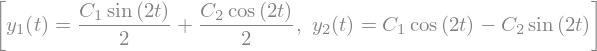

In [6]:
t = sp.symbols('t')
y1 = sp.Function('y1')
y2 = sp.Function('y2')
sol = sp.dsolve([sp.Eq(y1(t).diff(t), y2(t)),
                 sp.Eq(y2(t).diff(t), -4*y1(t))], [y1(t), y2(t)])
sol

As duas componentes são periódicas, com período $\pi$: a cada volta, a solução retorna ao ponto de partida, e as trajetórias são **curvas fechadas** (elipses $4y_1^2+y_2^2=\text{constante}$, como se verifica derivando essa expressão ao longo de uma solução).

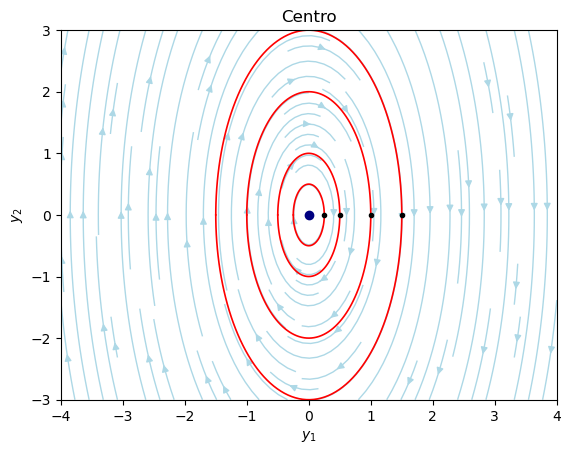

In [7]:
iniciais = [(0.25, 0), (0.5, 0), (1, 0), (1.5, 0)]
retrato_de_fase([[0, 1], [-4, 0]], iniciais=iniciais, T=np.pi/2)
plt.title('Centro')
plt.show()

Um **centro** é um ponto crítico cercado por uma infinidade de trajetórias fechadas. As soluções oscilam para sempre, sem se aproximar nem se afastar do ponto crítico.

### 11.5 Ponto espiral

**Exemplo 11.5:** O sistema
$$
\mathbf{y}^{\prime}=\left[\begin{array}{rr}
-1 & 1 \\
-1 & -1
\end{array}\right] \mathbf{y}, \quad \text { portanto, } \quad \begin{aligned}
& y_1^{\prime}=-y_1+y_2 \\
& y_2^{\prime}=-y_1-y_2
\end{aligned}
$$
tem a solução geral

In [8]:
sol = sp.dsolve([sp.Eq(y1(t).diff(t), -y1(t) + y2(t)),
                 sp.Eq(y2(t).diff(t), -y1(t) - y2(t))], [y1(t), y2(t)])
sol

As componentes são senos e cossenos (que fazem a solução girar em torno da origem) multiplicados por $e^{-t}$ (que faz a distância até a origem diminuir). O resultado são trajetórias em forma de **espiral** que se enrolam em direção à origem:

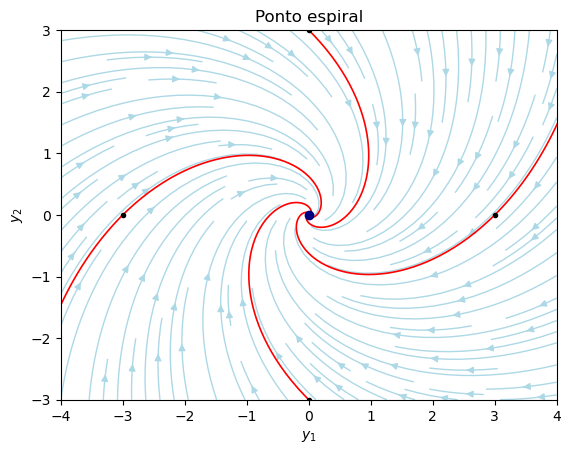

In [9]:
iniciais = [(3, 0), (-3, 0), (0, 3), (0, -3)]
retrato_de_fase([[-1, 1], [-1, -1]], iniciais=iniciais, T=5)
plt.title('Ponto espiral')
plt.show()

Um **ponto espiral** é um ponto crítico em torno do qual as trajetórias espiralam, aproximando-se dele à medida que $t \rightarrow \infty$ (ou, nos casos em que essas espirais são traçadas no sentido oposto, afastando-se dele). Note também o **sentido de rotação**: neste exemplo as trajetórias giram no sentido horário, o que se confirma olhando o campo em um ponto: em $(1,0)$, $\mathbf{y}'=(-1,-1)$ aponta para baixo.

#### Atividade 11.2

Desenhe o retrato de fase do sistema $y_1'=0,2y_1+y_2$, $y_2'=-y_1+0,2y_2$ no retângulo $[-4,4]\times[-3,3]$, com uma trajetória partindo de $(0,5;\ 0)$ calculada para $0\le t\le10$ (use `T=10`). Qual é o tipo do ponto crítico? As trajetórias se aproximam ou se afastam da origem? Em que sentido elas giram?

### 11.6 Estabilidade: uma primeira ideia

Os cinco exemplos mostram comportamentos bem diferentes quando $t\to\infty$:

| Exemplo | Tipo | Trajetórias próximas da origem... |
|---|---|---|
| 11.1 | nó impróprio | se aproximam dela |
| 11.2 | nó próprio | se afastam dela |
| 11.3 | ponto de sela | se afastam (exceto as duas que entram) |
| 11.4 | centro | giram em torno dela, sem se aproximar nem se afastar |
| 11.5 | ponto espiral | se aproximam dela, girando |

De modo intuitivo, um ponto crítico é **estável** se as soluções que começam perto dele continuam perto dele para sempre, e **instável** caso contrário. Se, além de continuar perto, elas **convergem** para o ponto crítico, ele é **assintoticamente estável**. Assim, os Exemplos 11.1 e 11.5 são assintoticamente estáveis, o 11.4 é estável (mas não assintoticamente) e os Exemplos 11.2 e 11.3 são instáveis.

O gráfico abaixo mostra a distância $\|\mathbf{y}(t)\|$ até a origem ao longo de uma solução de cada exemplo, todas partindo de $\mathbf{y}(0)=(1;\ 0,5)$:

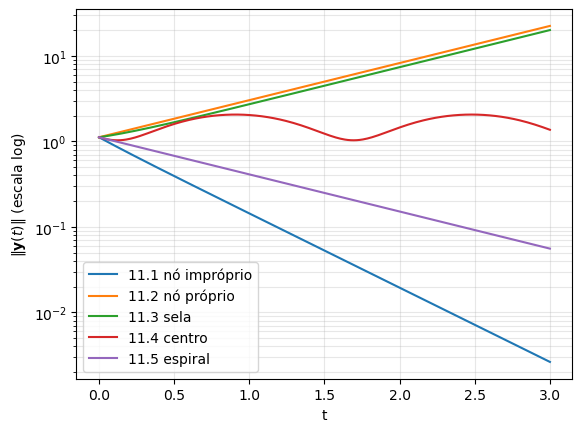

In [10]:
exemplos = {'11.1 nó impróprio': [[-3, 1], [1, -3]],
            '11.2 nó próprio':   [[1, 0], [0, 1]],
            '11.3 sela':         [[1, 0], [0, -1]],
            '11.4 centro':       [[0, 1], [-4, 0]],
            '11.5 espiral':      [[-1, 1], [-1, -1]]}
ts = np.linspace(0, 3, 300)
for nome, A in exemplos.items():
    A = np.array(A, dtype=float)
    s = solve_ivp(lambda t, y: A @ y, (0, 3), [1, 0.5], t_eval=ts, rtol=1e-8)
    plt.semilogy(s.t, np.linalg.norm(s.y, axis=0), label=nome)
plt.xlabel('t'); plt.ylabel('$\\|\\mathbf{y}(t)\\|$ (escala log)')
plt.legend(); plt.grid(which='both', alpha=0.3)
plt.show()

As definições formais de estabilidade e os critérios que permitem decidir o tipo e a estabilidade de um ponto crítico **sem desenhar** o retrato de fase — apenas olhando para os autovalores de $\mathbf{A}$ — são o assunto do Notebook 14.

### 11.7 Pontos críticos fora da origem

No Notebook 10 (Seção 10.4) vimos que o sistema autônomo $\mathbf{y}'=\mathbf{A}\mathbf{y}+\mathbf{b}$ tem ponto crítico $\mathbf{y}^*$ dado por $\mathbf{A}\mathbf{y}^*=-\mathbf{b}$. Fazendo a mudança de variável $\mathbf{z}=\mathbf{y}-\mathbf{y}^*$, temos

$$\mathbf{z}'=\mathbf{y}'=\mathbf{A}\mathbf{y}+\mathbf{b}=\mathbf{A}(\mathbf{z}+\mathbf{y}^*)+\mathbf{b}=\mathbf{A}\mathbf{z}+\underbrace{\mathbf{A}\mathbf{y}^*+\mathbf{b}}_{=\,\mathbf{0}}=\mathbf{A}\mathbf{z}.$$

Ou seja, o retrato de fase de $\mathbf{y}'=\mathbf{A}\mathbf{y}+\mathbf{b}$ é **o mesmo** de $\mathbf{z}'=\mathbf{A}\mathbf{z}$, apenas **transladado** para o ponto $\mathbf{y}^*$. O tipo e a estabilidade do ponto crítico dependem só da matriz $\mathbf{A}$.

**Exemplo 11.6:** (Adaptado de https://github.com/guerinileonardo) *Temperatura de uma estufa.* É importante que a temperatura de uma estufa se mantenha amena mesmo à noite, para criar as condições corretas para o desenvolvimento das plantas. Para isso, é criado um sistema de ventilação da seguinte forma.

Próximo à estufa, é construído um leito de rochas abaixo do solo, junto com isolantes térmicos. Assim, as rochas acumulam calor do sol durante o dia. À noite, o ar da estufa é ventilado através dessas rochas antes de retornar à estufa, com isso mantendo sua temperatura um pouco mais alta de maneira simples e barata.

<img src="https://raw.githubusercontent.com/tiagoburiol/MatComp_III/refs/heads/main/Notebook%2011%20-%20Retratos%20de%20fase%20e%20pontos%20cr%C3%ADticos/imagens/estufa.png" width="400">

Denotando por $u_1(t)$ a temperatura do ar dentro da estufa e por $u_2(t)$ a temperatura do leito de rochas no instante $t$ (temperaturas em °C), e levando em conta as massas de ar em cada local, a superfície de contato, o coeficiente de transferência de calor, os calores específicos e a temperatura externa, a lei da conservação de energia leva às seguintes equações diferenciais:

$$
\begin{cases}
\dfrac{du_1}{dt} = -\dfrac{13}{8}u_1 + \dfrac34 u_2 + 14 \\[2mm]
\dfrac{du_2}{dt} = \dfrac{1}{4}u_1 - \dfrac14 u_2.
\end{cases}
$$

Note que ambas as variações dependem tanto da temperatura da estufa, $u_1$, quanto da temperatura do leito de rochas, $u_2$. Em notação matricial, com

$$\textbf{u}={u_1\choose u_2}, \quad \textbf{K}=\begin{pmatrix} -\frac{13}{8} & \frac34 \\ \frac{1}{4} & -\frac14 \end{pmatrix},\quad \textbf{b} = {14 \choose 0},$$

o sistema é $\dfrac{d\textbf{u}}{dt} = \textbf{Ku} + \textbf{b}$.

Vamos assumir que o sistema de ventilação é acionado a partir de $t=0$, no início do anoitecer, quando a estufa está a $0\,$°C e o leito de rochas está a $36\,$°C, isto é, $\textbf{u}(0)=(0,\,36)$. Espera-se que a estufa vá retirando calor do leito de rochas.

**Ponto crítico.** Resolvendo $\textbf{K}\textbf{u}^*=-\textbf{b}$:

In [11]:
K = np.array([[-13/8, 3/4],
              [  1/4, -1/4]])
b = np.array([14, 0])
u_eq = np.linalg.solve(K, -b)
print(f'Ponto crítico: u1 = {u_eq[0]:.4f},  u2 = {u_eq[1]:.4f}')

Ponto crítico: u1 = 16.0000,  u2 = 16.0000


**Solução do PVI.** Pode-se verificar que

$$
\textbf{u}(t) = {8e^{-t/8} - 24e^{-7t/4} + 16 \choose 16e^{-t/8} + 4e^{-7t/4} + 16}
$$

é a solução do problema de valor inicial. Vamos conferir com o SymPy, calculando o resíduo $\textbf{u}'-\textbf{K}\textbf{u}-\textbf{b}$ e o valor em $t=0$ (usamos `sp.Rational` para trabalhar com as frações exatas):

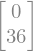

In [12]:
R = sp.Rational
K_s = sp.Matrix([[-R(13,8), R(3,4)], [R(1,4), -R(1,4)]])
b_s = sp.Matrix([14, 0])
u = sp.Matrix([8*sp.exp(-t/8) - 24*sp.exp(-R(7,4)*t) + 16,
               16*sp.exp(-t/8) + 4*sp.exp(-R(7,4)*t) + 16])
display(sp.simplify(u.diff(t) - K_s*u - b_s), u.subs(t, 0))

O resíduo é nulo e $\textbf{u}(0)=(0,36)$. Quando $t\to\infty$, as exponenciais vão a zero e $\textbf{u}(t)\to(16,16)$: as duas temperaturas se aproximam do ponto crítico. Vamos plotar $u_1(t)$ e $u_2(t)$ entre $t=0$ e $t=30$ e, ao lado, a mesma solução como trajetória no plano de fase:

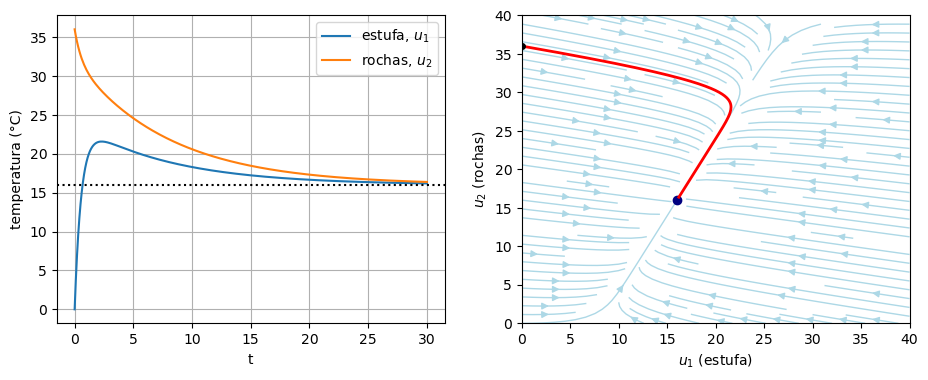

In [13]:
u1 = sp.lambdify(t, u[0])
u2 = sp.lambdify(t, u[1])
ts = np.linspace(0, 30, 300)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ts, u1(ts), label='estufa, $u_1$')
ax1.plot(ts, u2(ts), label='rochas, $u_2$')
ax1.axhline(16, color='k', ls=':')
ax1.set_xlabel('t'); ax1.set_ylabel('temperatura (°C)'); ax1.legend(); ax1.grid()

retrato_de_fase(K, b, xlim=(0, 40), ylim=(0, 40), ax=ax2)
ax2.plot(u1(ts), u2(ts), 'r-', lw=2)
ax2.plot(0, 36, 'ko', ms=4)
ax2.set_xlabel('$u_1$ (estufa)'); ax2.set_ylabel('$u_2$ (rochas)')
plt.show()

No plano de fase, a trajetória parte de $(0,36)$, avança rapidamente para a direita ($u_1$ cresce: no início a estufa esquenta depressa, retirando calor das rochas) e depois se aproxima do ponto crítico $(16,16)$ tangente a uma direção fixa: pelo retrato de fase, é um **nó impróprio assintoticamente estável**, deslocado para $(16,16)$. Qualquer que seja a temperatura inicial, as temperaturas da estufa e das rochas tendem a $16\,$°C.

#### Atividade 11.3

Considere o sistema $y_1'=-y_1+2y_2+3$, $y_2'=-2y_1-y_2-4$. Encontre o ponto crítico e desenhe o retrato de fase com `retrato_de_fase` num retângulo centrado nele, com algumas trajetórias. Qual é o tipo do ponto crítico? Ele é estável?

### 11.8 Exercícios

**1.** Desenhe o retrato de fase (linhas de fluxo e algumas trajetórias) do sistema

$$
\begin{cases}
y_1' = y_1 + y_2 \\
y_2' = 4y_1 + y_2
\end{cases}
$$

no retângulo $-4\le y_1\le4$, $-4\le y_2\le4$. Qual é o tipo do ponto crítico? Ele é estável?

**2.** Desenhe o retrato de fase do sistema abaixo, obtenha a solução geral com `sp.dsolve` e faça os gráficos de algumas soluções $y_1(t)$ e $y_2(t)$ em função de $t$. Qual é o tipo do ponto crítico?

$$
\begin{cases}
y_1' = -3y_1 + \sqrt{2}\, y_2 \\
y_2' = \sqrt{2}\,y_1 - 2y_2
\end{cases}
$$

**3.** (Brannan e Boyce, 2008, [fonte](https://integrada.minhabiblioteca.com.br/reader/books/978-85-216-2337-3/pageid/156)) Em cada um dos problemas a seguir, $(i)$ encontre a solução de equilíbrio (ponto crítico); $(ii)$ desenhe o retrato de fase centrado no ponto crítico; e $(iii)$ descreva o comportamento das soluções na vizinhança do ponto crítico (tipo e estabilidade).

$\begin{aligned}
&\text{(a)} \quad x^{\prime}=-x+y+1, \quad y^{\prime}=x+y-3 \\
&\text{(b)} \quad x^{\prime}=-x-4 y-4, \quad y^{\prime}=x-y-6 \\
&\text{(c)} \quad x^{\prime}=-0,25 x-0,75 y+8, \quad y^{\prime}=0,5 x+y-11,5 \\
&\text{(d)} \quad x^{\prime}=-2 x+y-11, \quad y^{\prime}=-5 x+4 y-35 \\
&\text{(e)} \quad x^{\prime}=x+y-3, \quad y^{\prime}=-x+y+1 \\
&\text{(f)} \quad x^{\prime}=-5 x+4 y-35, \quad y^{\prime}=-2 x+y-11
\end{aligned}$

**Referências**

BRANNAN, James R.; BOYCE, William E. Equações Diferenciais: uma Introdução a Métodos Modernos e suas Aplicações. São Paulo: Grupo GEN, 2008. E-book. ISBN 978-85-216-2337-3. Disponível em: https://integrada.minhabiblioteca.com.br/#/books/978-85-216-2337-3/.

KREYSZIG, Erwin. Matemática Superior para Engenharia. 9. ed. Rio de Janeiro: LTC, 2008. v. 2.